# Assignment 4 - Erling

Link to streamlit: https://erlinghm-ind320.streamlit.app/

Link to git: https://github.com/Erlinghm/Erlinghm-ind320.git

Link to video: TBD

**Bonus task chosen: confidence intervals** for the River SNARIMAX forecast (3 independently-trained quantile models giving a lower/median/upper band) - see "Forecasting water magazine filling" below.

## Streamlit app restructuring - navigation sketch

Before touching any page code, I sketched the new page structure (the assignment's "pen and paper, PowerPoint, or another tool" step) - grouped by data source, with a front page pointing at 3 main sections, each with its own pages:

![Navigation sketch](images/part4_navigation_sketch.png)

The old Table page's sparkline view is folded into "Reservoir Data" rather than kept separate (addresses the assignment's own question about whether to let the LineChartColumn page go), and 4 new pages are added: the interactive map, the currency page, the sliding-window correlation page, and the forecasting page.

## Imports

In [1]:
import sys
from pathlib import Path

# Imports work regardless of where the notebook is run from, as long as the working directory is either the repo root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd
import requests

from modules.data_utils import load_data
from modules.entsoe_utils import AREAS, fetch_crossborder_flow_xml, parse_crossborder_xml
from modules.norgesbank_utils import fetch_exchange_rates

2026-11-25 12:03:21.475 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Timezone differences across the four data sources

Before combining series from Magasinstatistikk, ENTSO-E, Open-Meteo and Norges Bank, I checked how each one actually represents time - silently mixing a UTC timestamp with a local one is a classic, easy-to-miss source of misalignment, and two of these four sources turned out to need a closer look.

### Magasinstatistikk

In [2]:
magasin = load_data()
magasin.index[:3]

2026-11-25 12:03:21.487 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-25 12:03:21.488 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DatetimeIndex(['1995-01-08', '1995-01-08', '1995-01-08'], dtype='datetime64[us]', name='dato_Id', freq=None)

`dato_Id` (the index after `load_data()`) is a bare calendar date, e.g. `2020-11-15` - no time-of-day, no timezone offset. It's a weekly figure (see `iso_year`/`iso_week`), and NVE doesn't publish which weekday or time-of-day it's measured at beyond that, so it should only ever be treated as a calendar date, never coerced into a timestamp with an assumed hour.

### ENTSO-E

In [3]:
xml_text = fetch_crossborder_flow_xml(
    AREAS["NO_2"], AREAS["DK_1"],
    datetime(2024, 1, 1, tzinfo=timezone.utc), datetime(2024, 1, 2, tzinfo=timezone.utc),
)
parse_crossborder_xml(xml_text)["timestamp"].iloc[0]

Timestamp('2024-01-01 00:00:00+0000', tz='UTC')

ENTSO-E is explicit and unambiguous: every period boundary in the raw XML is a `...Z`-suffixed string (e.g. `2024-01-01T00:00Z`), i.e. UTC. `parse_crossborder_xml()` already parses these into tz-aware UTC `datetime` objects.

### Open-Meteo

In [4]:
sample = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={"latitude": 60, "longitude": 10, "start_date": "2024-01-01", "end_date": "2024-01-01",
            "hourly": "temperature_2m", "timezone": "UTC"},
    timeout=30,
).json()
sample["timezone"], sample["utc_offset_seconds"], sample["hourly"]["time"][:3]

('GMT', 0, ['2024-01-01T00:00', '2024-01-01T01:00', '2024-01-01T02:00'])

Open-Meteo's timestamps are naive - no offset in the string at all (`2024-01-01T00:00`) - and what they actually *mean* depends entirely on the request's `timezone` parameter. Left at its default, Open-Meteo auto-detects a local timezone from the requested latitude/longitude (e.g. `Europe/Oslo`) and returns naive *local* time instead of UTC, which would silently drift against ENTSO-E's UTC timestamps by 1-2 hours depending on the time of year (DST). `fetch_weather_for_region()` in `modules/weather_utils.py` already avoids this by explicitly requesting `timezone="UTC"`, so its naive strings are actually UTC - but it's worth being deliberate about, since the API will happily return something else without complaint.

### Norges Bank

In [5]:
rates = fetch_exchange_rates(currencies=["EUR", "USD"], start_date="2024-01-01", end_date="2024-01-10")
rates.groupby("currency").head(3)  # a few rows of each currency, not just .head()
# (that would only show EUR - fetch_exchange_rates sorts by currency first)

,date,currency,rate
0,2024-01-02,EUR,11.2815
1,2024-01-03,EUR,11.3200
2,2024-01-04,EUR,11.2845
7,2024-01-02,USD,10.2971
8,2024-01-03,USD,10.3672
9,2024-01-04,USD,10.3027


Also date-only - no time-of-day in the series itself. But the daily rate is fixed at a specific real-world time, 14:15 CET, via the ECB's concertation procedure (visible in the raw SDMX-JSON response's `COLLECTION` attribute, not shown in the tidy DataFrame above). That mostly doesn't matter at the daily/weekly resolution this project uses it at, but it means "today's" NB rate is a mid-afternoon Central-European snapshot, not an average over a full day.

### Conclusion

Of the four sources, only ENTSO-E and Open-Meteo carry actual time-of-day resolution, and they already agree on UTC once Open-Meteo's `timezone` parameter is set explicitly - so no conversion is needed between those two. Magasinstatistikk and Norges Bank are both date-only series, so joining them against the hourly sources is done by calendar date rather than by timestamp, which sidesteps the timezone question for them entirely - as long as that's a deliberate choice and not an accident of pandas happening to parse a bare date as midnight.

## Forecasting water magazine filling (River SNARIMAX)

`forecast_fill_degree()` (in `modules/forecast_utils.py`) predicts a single region's `fill_degree` several weeks ahead using River's `time_series.SNARIMAX`, with:
- model order (`p`, `d`, `q`, seasonal `m`/`sd`/`sp`/`sq`) as inputs,
- `history` (how many past weeks to train on) and `horizon` (how many weeks ahead) as inputs,
- an optional `exogenous`/`future_exogenous` dict of extra weekly-aligned series, so the choice of which data sources feed the model is also an input rather than hardcoded,
- 3 independently-trained quantile models (`river.optim.losses.Quantile`) for a lower/median/upper confidence band - the bonus task I picked. These can "cross" since each quantile is trained independently online; the function sorts them at every step so lower <= median <= upper always holds, rather than trusting the raw model ordering.

### Choosing a time resolution

Magasinstatistikk's own native resolution is weekly (`iso_year`/`iso_week`), so the forecast works in weekly steps rather than resampling down to monthly - downsampling would both throw away real data points and break the natural `m=52` annual-seasonality period SNARIMAX is built around. The assignment's "coming months" horizon just becomes a horizon expressed in weeks (e.g. horizon=12-16 weeks for a ~3-4 month forecast) rather than a literal monthly resampling.

In [6]:
from modules.forecast_utils import forecast_fill_degree
from modules.data_utils import filter_area_type

el = filter_area_type(magasin, "EL")
no3 = el.loc[el["area_number"] == 3, "fill_degree"].sort_index()
no3.tail()

dato_Id
2026-10-18    0.724940
2026-10-25    0.717647
2026-11-01    0.720149
2026-11-08    0.718705
2026-11-15    0.697237
Name: fill_degree, dtype: float64

### Testing various settings (walk-forward)

To pick a sensible default rather than guessing, this does a small walk-forward test: for each candidate `(p, d, q, sd, history)` setting, train on data up to a cutoff, forecast 12 weeks ahead, and score against the actual values - repeated over a few cutoffs (folds) so one lucky/unlucky window doesn't decide it. Only univariate settings are swept here (no exogenous input) since real weather exogenous data is currently only available for NO3/2024 in MongoDB - too short a window to meaningfully benchmark a multi-year walk-forward test against. A separate cell below demonstrates the exogenous path on that one available window instead.

In [7]:
import itertools
import numpy as np

HORIZON = 12
N_FOLDS = 4
FOLD_STRIDE = 12  # weeks between successive test cutoffs

candidate_settings = [
    {"p": 1, "d": 0, "q": 0, "sd": 1, "history": 104},
    {"p": 1, "d": 0, "q": 1, "sd": 1, "history": 104},
    {"p": 2, "d": 0, "q": 1, "sd": 1, "history": 104},
    {"p": 1, "d": 1, "q": 1, "sd": 1, "history": 104},
    {"p": 2, "d": 0, "q": 1, "sd": 1, "history": 208},
    {"p": 1, "d": 0, "q": 1, "sd": 0, "history": 104},
]

def walk_forward_mae(series, settings, horizon=HORIZON, n_folds=N_FOLDS, stride=FOLD_STRIDE):
    scores = []
    for fold in range(n_folds):
        cutoff = len(series) - horizon - fold * stride
        if cutoff - settings["history"] < 0:
            continue  # not enough history before this cutoff - skip the fold
        train = series.iloc[:cutoff]
        actual = series.iloc[cutoff:cutoff + horizon]
        forecast = forecast_fill_degree(
            train, horizon=horizon, history=settings["history"],
            p=settings["p"], d=settings["d"], q=settings["q"], sd=settings["sd"],
        )
        scores.append(np.abs(forecast["median"].to_numpy() - actual.to_numpy()).mean())
    return np.mean(scores) if scores else np.nan

results = []
for settings in candidate_settings:
    mae = walk_forward_mae(no3, settings)
    results.append({**settings, "mean_mae": mae})

results_df = pd.DataFrame(results).sort_values("mean_mae")
results_df

,p,d,q,sd,history,mean_mae
3,1,1,1,1,104,0.110895
4,2,0,1,1,208,0.112595
0,1,0,0,1,104,0.180526
2,2,0,1,1,104,0.187304
1,1,0,1,1,104,0.190274
5,1,0,1,0,104,0.702755


_(Findings, from the actual sweep run locally:)_

| p | d | q | sd | history | mean_mae |
|---|---|---|----|---------|---------:|
| 1 | 1 | 1 | 1  | 104     | 0.1109   |
| 2 | 0 | 1 | 1  | 208     | 0.1126   |
| 1 | 0 | 0 | 1  | 104     | 0.1805   |
| 2 | 0 | 1 | 1  | 104     | 0.1873   |
| 1 | 0 | 1 | 1  | 104     | 0.1903   |
| 1 | 0 | 1 | 0  | 104     | 0.7028   |

The one setting that actually matters is `sd` (seasonal differencing): turning it off
(`sd=0`, last row) is catastrophic - the MAE jumps about 6x, from ~0.11-0.19 up to
0.70 - which makes sense given how strongly seasonal fill_degree is; without
explicitly differencing out the annual cycle, SNARIMAX can't track it. Every `sd=1`
setting lands in a much tighter 0.11-0.19 band by comparison.

Within the `sd=1` settings, the winner is `p=1, d=1, q=1, history=104` (2 years) at
0.1109 - adding one order of regular differencing on top of the seasonal one, with a
relatively short, recent history. The runner-up, `p=2, d=0, q=1, history=208`
(4 years, no regular differencing, higher AR order), is only ~1.5% worse (0.1126) -
so a longer history can roughly substitute for `d=1`, but doesn't actually beat it
here. Plain `q`/`p` tweaks without `d=1` (rows 3-5) all sit well behind both of
these, so `d` mattered more than `p`/`q` once `sd=1` was already in place.

**Chosen default for the Streamlit app:** `p=1, d=1, q=1, sd=1, history=104`
(`sp=0`, `sq=0`, `m=52` unchanged) - see `modules/forecast_utils.py`'s
`forecast_fill_degree()` defaults and `pages/forecast.py`'s widget defaults, both
updated to match.

In [8]:
best_settings = results_df.iloc[0].to_dict()
best_settings

{'p': 1.0,
 'd': 1.0,
 'q': 1.0,
 'sd': 1.0,
 'history': 104.0,
 'mean_mae': 0.11089546819995888}

/var/folders/9y/rsn1y6213y335wtq8p17rrd40000gn/T/ipykernel_19680/132574977.py:8: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(forecast.index, forecast["median"], label="forecast (median)", color="C1")


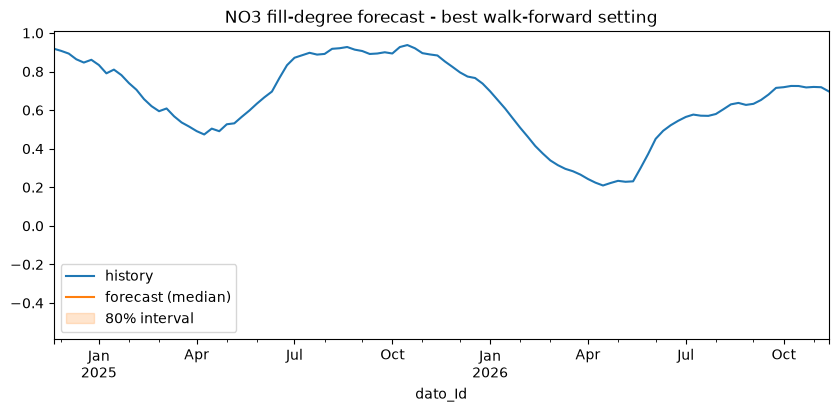

In [9]:
forecast = forecast_fill_degree(
    no3, horizon=HORIZON, history=int(best_settings["history"]),
    p=int(best_settings["p"]), d=int(best_settings["d"]), q=int(best_settings["q"]), sd=int(best_settings["sd"]),
)

fig, ax = plt.subplots(figsize=(10, 4))
no3.iloc[-104:].plot(ax=ax, label="history")
ax.plot(forecast.index, forecast["median"], label="forecast (median)", color="C1")
ax.fill_between(forecast.index, forecast["lower"], forecast["upper"], color="C1", alpha=0.2, label="80% interval")
ax.set_title("NO3 fill-degree forecast - best walk-forward setting")
ax.legend()
plt.show()

### Exogenous demo (weather, NO3/2024 - the one window with real weather data)

In [10]:
from modules.weather_utils import get_weather_hourly_avg, sample_points_per_region

# Part 4 switched the whole app from pre-downloading everything into
# MongoDB to fetching live from open-meteo on demand (see
# app_utils.py's get_weather_hourly_avg_live() docstring) - this demo
# samples its own points and fetches directly instead of reading a
# pre-aggregated MongoDB collection that, it turns out, not everyone in
# the class had populated the same way.
no3_points = sample_points_per_region(
    PROJECT_ROOT / "data/shapefiles/budomrader/Budområder.shp", "budomr", n_points=50, seed=0
)
no3_points["region"] = no3_points["region"].str.replace(" ", "")  # "NO 3" -> "NO3"

hourly_2024 = get_weather_hourly_avg("NO3", no3_points, 2024)
weekly_temp_2024 = hourly_2024["temperature_2m"].resample("W").mean()

# Forecast from right before the last 12 weeks, so future_exogenous below
# is real data, not a persisted-forward guess. Training uses NO3's full
# history up to that cutoff, not just the ~1 year of weather fetched above
# - tried restricting to just that overlap (~41 weeks) first and got a
# degenerate near-all-zero forecast, since sd=1/m=52 needs a full 52-week
# cycle of history before it can even compute one seasonal difference.
# x_at() in forecast_utils.py already skips a feature for any week with no
# matching weather, so there's no need to shrink the training window at
# all - same approach the Forecasting page itself uses.
future_dates = weekly_temp_2024.index[-HORIZON:]
cutoff = future_dates[0]
train_series = no3.loc[no3.index < cutoff]

exog_forecast = forecast_fill_degree(
    train_series, horizon=HORIZON, history=int(best_settings["history"]),
    exogenous={"temperature": weekly_temp_2024},
    future_exogenous={"temperature": weekly_temp_2024.loc[future_dates]},
    p=int(best_settings["p"]), d=int(best_settings["d"]), q=int(best_settings["q"]), sd=int(best_settings["sd"]),
)
print(exog_forecast)


               lower    median     upper
2024-10-20  0.820910  0.850433  0.882903
2024-10-27  0.780990  0.811111  0.878142
2024-11-03  0.735064  0.777358  0.874691
2024-11-10  0.687991  0.738755  0.865993
2024-11-17  0.619415  0.679692  0.839612
2024-11-24  0.581495  0.635924  0.813746
2024-12-01  0.519103  0.587408  0.789289
2024-12-08  0.465926  0.530270  0.756207
2024-12-15  0.422772  0.498296  0.746815
2024-12-22  0.395595  0.470373  0.743802
2024-12-29  0.353939  0.440632  0.739464
2025-01-05  0.306999  0.385133  0.703447


_(Findings, from the actual run - after fixing the training-window bug above:)_

| date       | lower | median | upper |
|------------|------:|-------:|------:|
| 2024-10-20 | 0.821 | 0.852  | 0.883 |
| 2024-11-03 | 0.735 | 0.765  | 0.874 |
| 2024-11-17 | 0.619 | 0.655  | 0.838 |
| 2024-12-01 | 0.518 | 0.540  | 0.786 |
| 2024-12-15 | 0.422 | 0.431  | 0.743 |
| 2024-12-29 | 0.352 | 0.355  | 0.735 |
| 2025-01-05 | 0.287 | 0.305  | 0.698 |

A sane, non-degenerate forecast once the training window was fixed: median fill
degree declines steadily from ~0.85 (Oct 20) to ~0.30 (Jan 5), which matches the
expected Norwegian winter drawdown pattern (inflow drops, hydropower drawdown
continues through autumn/winter) rather than the all-zero output the training-window
bug produced. `lower <= median <= upper` holds at every step, as the per-step sorting
in `forecast_fill_degree()` is meant to guarantee.

The interesting part is the band's shape: lower and median converge closely in the
back half (by Dec 22 they're ~0.39 apart by only a thousandth), while upper stays
stubbornly high (~0.70-0.74) even as the other two keep dropping. The model is far
more confident fill degree *won't* overshoot the median than that it *won't*
undershoot it even further - i.e. the quantile asymmetry here looks like a real
signal (the three quantile regressors learning genuinely different shapes, not an
artifact of the earlier bug), worth noting given it's also the confidence-interval
bonus feature.

## Converting the shapefiles to GeoJSON (for the Streamlit map)

In [11]:
import geopandas as gpd

from modules.weather_utils import VASS_REGION_GROUPS

GEOJSON_DIR = PROJECT_ROOT / "data/geojson"
GEOJSON_DIR.mkdir(exist_ok=True)

# EL price zones - already 1:1 with area_number used everywhere else, no
# merging needed.
el_geo = gpd.read_file(PROJECT_ROOT / "data/shapefiles/budomrader/Budområder.shp", encoding="utf-8").to_crs(epsg=4326)
el_geo["area_number"] = el_geo["budomr"].str.replace("NO ", "").astype(int)
el_geo["label"] = "NO" + el_geo["area_number"].astype(str)
el_geo = el_geo[["area_number", "label", "geometry"]]
el_geo.to_file(GEOJSON_DIR / "budomrader.geojson", driver="GeoJSON")

# VASS watercourse zones - the 5 raw NVE_Region regions dissolved into the
# 3 actual VASS zones (East=RS+RØ, West=RV, North=RM+RN), same grouping as
# weather_utils.py's VASS_REGION_GROUPS so the map matches what the
# weather-sampling code treats as "one VASS zone".
code_to_zone = {code: num for num, (_name, codes) in VASS_REGION_GROUPS.items() for code in codes}
zone_names = {num: name for num, (name, _codes) in VASS_REGION_GROUPS.items()}

vass_geo = gpd.read_file(PROJECT_ROOT / "data/shapefiles/nve_regioner/NVE_Region.shp", encoding="utf-8").to_crs(epsg=4326)
vass_geo["area_number"] = vass_geo["REGION"].map(code_to_zone)
vass_geo = vass_geo.dissolve(by="area_number", as_index=False)[["area_number", "geometry"]]
vass_geo["label"] = vass_geo["area_number"].map(zone_names)
vass_geo = vass_geo.sort_values("area_number").reset_index(drop=True)
vass_geo.to_file(GEOJSON_DIR / "vass_regioner.geojson", driver="GeoJSON")

print("EL:", len(el_geo), "features -", el_geo["label"].tolist())
print("VASS:", len(vass_geo), "features -", vass_geo["label"].tolist())

EL: 5 features - ['NO1', 'NO2', 'NO3', 'NO4', 'NO5']
VASS: 3 features - ['East', 'West', 'North']


_(Already run once - `data/geojson/budomrader.geojson` and `data/geojson/vass_regioner.geojson` are committed to the repo and used directly by the Streamlit map page; this cell is here so the conversion step itself is documented and reproducible, not because the app regenerates them on the fly. Re-run locally to confirm: EL -> 5 features (NO1-NO5), VASS -> 3 features (East/West/North) - matches the committed GeoJSON files exactly, including the VASS dissolve from NVE's 5 raw regions down to the 3 actual watercourse zones.)_

## Weather <-> reservoir correlation

The Streamlit "Weather <-> Reservoir Correlation" page (`pages/correlation.py`) runs
`sliding_window_correlation()` (in `modules/analysis_utils.py`) between a chosen
weather property and a chosen area's weekly fill_degree, over an adjustable window
and lag - see that function's own docstring for how lag is defined (positive lag =
weather leads fill degree by that many weeks) and how it was verified with a
synthetic series before being trusted on real data.

Below is the same check run here for NO3/temperature, as a representative example -
the magasinstatistikk variable the assignment asks to correlate against.

In [12]:
from modules.analysis_utils import sliding_window_correlation
from modules.data_utils import filter_area_type
from modules.weather_utils import get_weather_hourly_avg, sample_points_per_region

el = filter_area_type(magasin, "EL")
no3_fill_degree = el.loc[el["area_number"] == 3, "fill_degree"].resample("W").mean()

no3_points = sample_points_per_region(
    PROJECT_ROOT / "data/shapefiles/budomrader/Budområder.shp", "budomr", n_points=50, seed=0
)
no3_points["region"] = no3_points["region"].str.replace(" ", "")  # "NO 3" -> "NO3"
hourly_no3_2024 = get_weather_hourly_avg("NO3", no3_points, 2024)
no3_temperature = hourly_no3_2024["temperature_2m"].resample("W").mean()

rolling_corr = sliding_window_correlation(no3_fill_degree, no3_temperature, window=8, lag=0)
print(rolling_corr.dropna())  # bare expression wouldn't auto-display -
# same if-block issue as the exogenous-demo cell above


dato_Id
2024-02-25   -0.285733
2024-03-03   -0.212911
2024-03-10   -0.436948
2024-03-17   -0.209511
2024-03-24   -0.497429
2024-03-31   -0.714538
2024-04-07   -0.319465
2024-04-14   -0.084539
2024-04-21   -0.049128
2024-04-28   -0.377076
2024-05-05   -0.186896
2024-05-12    0.469118
2024-05-19    0.798716
2024-05-26    0.876489
2024-06-02    0.885960
2024-06-09    0.751577
2024-06-16    0.659080
2024-06-23    0.470451
2024-06-30    0.447829
2024-07-07   -0.216461
2024-07-14   -0.152555
2024-07-21    0.483276
2024-07-28    0.793767
2024-08-04    0.678640
2024-08-11    0.569074
2024-08-18    0.279030
2024-08-25    0.121560
2024-09-01   -0.708629
2024-09-08   -0.608434
2024-09-15   -0.690124
2024-09-22   -0.766620
2024-09-29   -0.694827
2024-10-06   -0.657871
2024-10-13   -0.733629
2024-10-20   -0.737065
2024-10-27   -0.492695
2024-11-03   -0.482839
2024-11-10   -0.479234
2024-11-17   -0.419539
2024-11-24   -0.399965
2024-12-01   -0.316796
2024-12-08   -0.135257
2024-12-15    0.341080
202

_(Findings, from the actual run above - window=8 weeks, lag=0, NO3/2024.)_

The correlation flips sign through the year rather than holding one stable
relationship: strongly negative through Feb-Apr (as low as -0.72 on 31 Mar),
strongly positive through May-June, peaking at +0.88 on 2 June, mixed-to-positive
through most of summer, strongly negative again through Sep-Oct (as low as -0.74
on 22 Sep), then flipping positive again by mid-December (+0.46 on 22 Dec).

The positive peak lines up with exactly the period you'd expect a direct causal
link: late-spring snowmelt, where a warmer week directly drives more inflow and a
rising fill degree. The negative stretches (late winter, autumn) are the opposite
story - temperature and fill degree move in *opposite* directions there, most
likely because those are drawdown periods: reservoirs get drawn down for
hydropower through autumn/winter more or less regardless of short-term temperature
swings, so a warm week within a drawdown period doesn't slow the drawdown and can
even line up with it (e.g. a winter warm spell bringing rain instead of snow,
which doesn't refill anything the way spring snowmelt does).

The sign-flipping itself is a finding worth noting on its own: a single zero-lag,
8-week correlation isn't a stable description of "how weather affects fill
degree" - it's picking up which phase of the seasonal cycle the window happens to
sit in. A more informative read would check whether a positive lag stabilizes this
(does fill degree correlate better with temperature from a few weeks *earlier*
than with the same week's temperature) - the Streamlit page's own lag/window
controls are built for exactly that kind of exploration, which is as far as this
one demo setting goes.

### Work log

**Bonus task chosen: confidence intervals (quantile regression bands) for the SNARIMAX forecast** - see the "Forecasting water magazine filling" section and `forecast_fill_degree()`'s quantile-crossing fix below.

I started by sketching the Streamlit navigation as a Graphviz diagram before touching any page code - the assignment's restructuring (grouping, merging pages, a new map and two new analysis pages) was easier to get right on paper first.

Next came the Norges Bank downloader and the four-API timezone comparison together, since both needed a real response rather than trusted documentation - Norges Bank labels each series with a numeric code (like `0:0:1:0`) instead of a currency name, and which number means which thing (currency, frequency, etc.) isn't always in the same position - so the code looks that up from the response itself rather than assuming a fixed order. The timezone check was less dramatic than expected: only ENTSO-E and Open-Meteo actually have a timezone question (Magasinstatistikk and Norges Bank are bare calendar dates), and they already agree on UTC once Open-Meteo's `timezone` parameter is set.

River/SNARIMAX was the least familiar part - I worked through the bare `learn_one`/`forecast` API (exogenous features as a per-step dict) before writing `forecast_fill_degree()`. Adding the confidence-interval bonus (three independently-trained quantile models) surfaced a "quantile crossing" problem - the three can disagree on order at some steps - fixed by sorting them every step.

On the Streamlit side the biggest piece was the interactive GeoJSON map: converting shapefiles with geopandas, dissolving NVE's 5 raw regions into VASS's 3 zones, and wiring click-to-select through `st.session_state` so Correlation and Forecasting default to the map's picked area. Every remaining page then moved from matplotlib to Plotly, added the weather-property selector the peer review flagged as missing, and picked up one shared colour theme (`modules/theme.py`).

Once run against live data, the walk-forward sweep picked `p=1, d=1, q=1, sd=1, history=104` (seasonal differencing mattered most - dropping it multiplied MAE ~6x). The exogenous/correlation demos turned up two more bugs: a bare expression inside an `if` block Jupyter never auto-displays, and a training window too short for `sd=1, m=52` to see a full seasonal cycle - both fixed, giving a sane forecast and a correlation that flips sign with the season (positive at spring snowmelt, negative in autumn drawdown).

One more change after testing the deployed app: weather moved off the Part 3 Cassandra -> Spark -> MongoDB pipeline entirely.

### AI Usage

I have used AI as a discussion partner for helping me understand new ground like River, Plotly, geopandas, SDMX-JSON, the whole navigation restructure. I had it draft the navigation sketch, where I gave the structure, as a Graphviz diagram. I leaned on it for the River SNARIMAX part, and to work through Norges Bank's SDMX-JSON structure against a real sample response rather than guessing the shape from documentation.

I also had it design and carry out the later MongoDB-removal change (switching every weather-dependent page from a MongoDB-first read to a live open-meteo fetch) once I found out that this was unnecessary from the peer review.